# 22. Unsupervised Learning III: Clustering
@Shengli (Bruce) Jiang, University of South Carolina

## What We Have Covered

So far, we have worked with:

- Python, NumPy, pandas, and plotting
- regression, model evaluation, uncertainty, and regularization
- feature scaling, encoding, and hyperparameter tuning
- classification with logistic regression, SVMs, trees, and random forests
- imbalanced data and neural-network training
- unsupervised learning, PCA, kernel PCA, t-SNE, and UMAP

Today we look for groups in the data.

## What We Covered in the Last Lecture

Last time, we used kernel PCA for the liquid-crystal rings, then t-SNE and UMAP for the wine data.

We also looked at:

- how the settings change the map
- how UMAP places new samples in a fitted map
- distance between numerical features
- similarity between fingerprints

Now we use these features and distances to find groups.

## Today's Learning Objectives

By the end of this notebook, you should be able to:

1. Run K-means and explain how it updates the centers.
2. Compare different `k` using inertia and silhouette score.
3. Explain why scaling changes the clusters.
4. Use K-medoids with molecular fingerprints.
5. Compare K-means and DBSCAN on curved data.

## Running the Notebook

Run the cells from top to bottom.

The wine data come with scikit-learn. We generate the reactor and curved data here, so no data download is needed.

We use seed 26, same as before.

In [1]:
%matplotlib inline

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import load_wine, make_moons
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, pairwise_distances
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 26
rng = np.random.default_rng(SEED)
plt.rcParams.update({"font.size": 11})

## 1. K-means on the Wine Data

We have 178 samples and 13 chemical measurements.

Last time, we used these measurements to make a map. Today we want to put similar samples into groups.

We still fit using `X` only. Keep the wine labels for checking the result later.

In [2]:
wine = load_wine(as_frame=True)
X_wine = wine.data.copy()
y_wine_hidden = wine.target.to_numpy()

scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)

print("Samples:", X_wine.shape[0])
print("Chemical measurements:", X_wine.shape[1])
display(X_wine.head())

Samples: 178
Chemical measurements: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### The First Run

K-means puts nearby samples into groups around a center. We choose the number of groups, `k`.

Let's try `k=3` first.

We fit on all 13 standardized features. PCA is just for plotting the result in 2D.

`n_init=20` means try 20 starts and keep the one with the smallest sum of squared distances. A bad starting point can give a worse result.

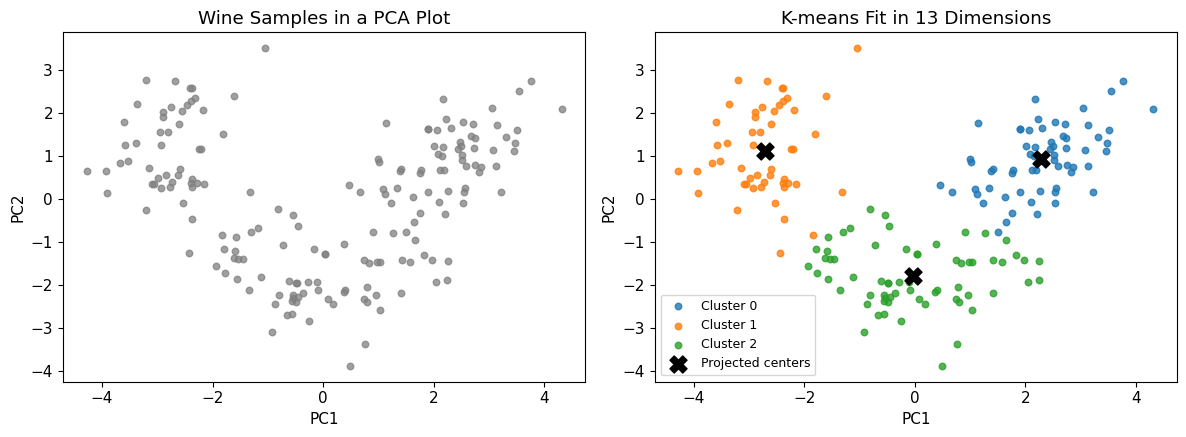

In [17]:
kmeans_wine = KMeans(n_clusters=3, n_init=20, random_state=SEED)
cluster_wine = kmeans_wine.fit_predict(X_wine_scaled)

pca_wine = PCA(n_components=2)
wine_scores = pca_wine.fit_transform(X_wine_scaled)
centers_2d = pca_wine.transform(kmeans_wine.cluster_centers_)


def plot_clusters(ax, coordinates, labels, title):
    for cluster_id in np.unique(labels):
        mask = labels == cluster_id
        if cluster_id == -1:
            ax.scatter(coordinates[mask, 0], coordinates[mask, 1],
                       color="0.55", marker="x", s=24, label="Noise")
        else:
            ax.scatter(coordinates[mask, 0], coordinates[mask, 1],
                       s=22, alpha=0.8, label=f"Cluster {cluster_id}")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(wine_scores[:, 0], wine_scores[:, 1],
                color="0.5", s=22, alpha=0.75)
axes[0].set_title("Wine Samples in a PCA Plot")
plot_clusters(axes[1], wine_scores, cluster_wine, "K-means Fit in 13 Dimensions")
axes[1].scatter(centers_2d[:, 0], centers_2d[:, 1],
                color="black", marker="X", s=150, label="Projected centers")

for ax in axes:
    ax.set(xlabel="PC1", ylabel="PC2")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

The coordinates are the same in both plots. On the right, we color the points by their K-means group.

The black crosses are the centers, also projected with PCA.

Now let's compare the groups with the actual wine labels.

In [4]:
comparison = pd.crosstab(
    pd.Series(y_wine_hidden, name="Known cultivar"),
    pd.Series(cluster_wine, name="K-means cluster")
)
display(comparison)

ari_wine = adjusted_rand_score(y_wine_hidden, cluster_wine)
print("Adjusted Rand index:", round(ari_wine, 3))

K-means cluster,0,1,2
Known cultivar,,,
0,59,0,0
1,3,3,65
2,0,48,0


Adjusted Rand index: 0.897


In the table, rows are the wine classes and columns are the K-means groups.

The group numbers do not have to match the class numbers. Cluster 0 could contain mostly class 1, for example.

ARI compares the two groupings. 1 means the same grouping, even if the numbers are different. Around 0 means little agreement.

## 2. How Does K-means Update the Centers?

K-means is pretty simple:

1. Choose how many clusters we want, `k`.
2. Start with `k` centers.
3. Put each point in the group with the nearest center.
4. Calculate the mean of each group. These are the new centers.
5. Repeat the last two steps.

We want the points to stay close to their own center. So we minimize

$$\mathrm{WSS} = \sum_{c=1}^{k}\sum_{i\in C_c}
\|\mathbf{x}_i-\boldsymbol{\mu}_c\|^2.$$

Let's follow the updates with six measurements. Use two centers, starting at 2 and 3.

In [18]:
toy_values = np.array([1, 2, 3, 8, 9, 10], dtype=float)
initial_centers = np.array([2.0, 3.0])

squared_distances = (toy_values[:, None] - initial_centers[None, :])**2
first_assignment = squared_distances.argmin(axis=1)
updated_centers = np.array([
    toy_values[first_assignment == c].mean() for c in range(2)
])

display(pd.DataFrame({
    "Measurement": toy_values,
    "First cluster assignment": first_assignment
}))
display(pd.DataFrame({
    "Cluster": [0, 1],
    "Initial center": initial_centers,
    "Center after first update": updated_centers
}))

,Measurement,First cluster assignment
0,1.0,0
1,2.0,0
2,3.0,1
3,8.0,1
4,9.0,1
5,10.0,1


,Cluster,Initial center,Center after first update
0,0,2.0,1.5
1,1,3.0,7.5


The centers moved to 1.5 and 7.5.

Now assign the points again. The point at 3 is closer to 1.5, so it changes its group.

Calculate the means one more time. We should get 2 and 9.

In [6]:
second_assignment = (
    (toy_values[:, None] - updated_centers[None, :])**2
).argmin(axis=1)

final_centers = np.array([
    toy_values[second_assignment == c].mean() for c in range(2)
])

display(pd.DataFrame({
    "Measurement": toy_values,
    "First assignment": first_assignment,
    "Second assignment": second_assignment
}))
print("Centers after the second update:", final_centers)

toy_kmeans = KMeans(n_clusters=2, init=initial_centers[:, None],
                    n_init=1, random_state=SEED).fit(toy_values[:, None])
print("Centers from scikit-learn:", np.sort(toy_kmeans.cluster_centers_.ravel()))
print("Within-cluster sum of squares:", toy_kmeans.inertia_)

,Measurement,First assignment,Second assignment
0,1.0,0,0
1,2.0,0,0
2,3.0,1,0
3,8.0,1,1
4,9.0,1,1
5,10.0,1,1


Centers after the second update: [2. 9.]
Centers from scikit-learn: [2. 9.]
Within-cluster sum of squares: 4.0


## 3. How Many Clusters?

We picked `k=3`. What if we use 2, 4, or more?

First look at the within-cluster sum of squares. scikit-learn calls this **inertia**.

More groups can make the distances smaller. If every point has its own group, the inertia is zero. So we cannot just choose the smallest value.

The elbow method looks for where the improvement starts slowing down. Let's plot inertia and silhouette for several values of `k`.

,k,Inertia,Silhouette
0,1,2314.000,NaN
1,2,1658.759,0.259
2,3,1277.928,0.285
3,4,1175.705,0.252
4,5,1107.404,0.241
5,6,1049.531,0.166
6,7,991.754,0.193


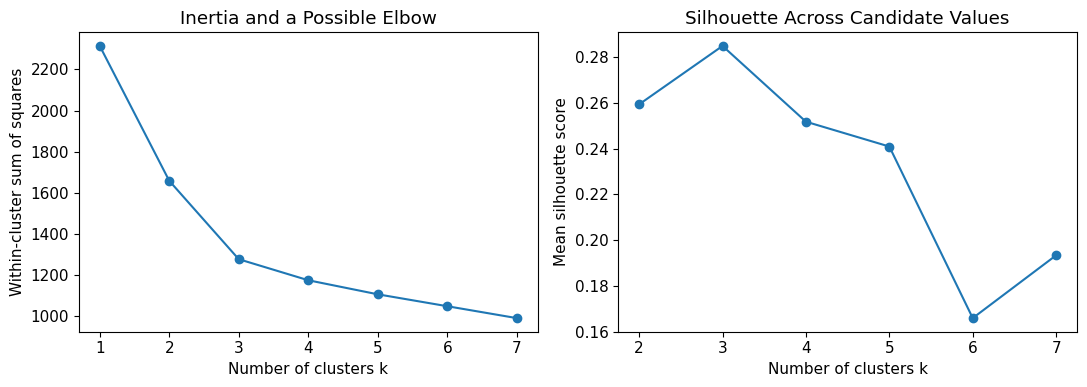

In [19]:
rows = []
for k in range(1, 8):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(X_wine_scaled)
    score = silhouette_score(X_wine_scaled, labels) if k > 1 else np.nan
    rows.append({"k": k, "Inertia": model.inertia_, "Silhouette": score})

k_results = pd.DataFrame(rows)
display(k_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_results["k"], k_results["Inertia"], marker="o")
axes[0].set(xlabel="Number of clusters k", ylabel="Within-cluster sum of squares",
            title="Inertia and a Possible Elbow")
axes[1].plot(k_results["k"], k_results["Silhouette"], marker="o")
axes[1].set(xlabel="Number of clusters k", ylabel="Mean silhouette score",
            title="Silhouette Across Candidate Values")
fig.tight_layout()
plt.show()

### Silhouette Score

For one point $i$, calculate:

- $a_i$: average distance to the other points in its own group
- $b_i$: average distance to the nearest other group

Here "nearest group" means the one with the smallest average distance.

$$s_i = \frac{b_i-a_i}{\max(a_i,b_i)}.$$

Close to 1 means the point fits its group well. Close to 0 means it is between groups. A negative value means another group is closer on average.

Let's calculate it for the wine sample with the lowest score and compare with scikit-learn.

In [8]:
sample_silhouettes = silhouette_samples(X_wine_scaled, cluster_wine)
i = int(np.argmin(sample_silhouettes))
D_wine = pairwise_distances(X_wine_scaled)

own_cluster = cluster_wine == cluster_wine[i]
own_cluster[i] = False
a_i = D_wine[i, own_cluster].mean()

b_i = min(
    D_wine[i, cluster_wine == c].mean()
    for c in np.unique(cluster_wine) if c != cluster_wine[i]
)
manual_silhouette = (b_i - a_i) / max(a_i, b_i)

display(pd.DataFrame({
    "Sample index": [i], "a": [a_i], "b": [b_i],
    "Manual silhouette": [manual_silhouette],
    "sklearn silhouette": [sample_silhouettes[i]]
}).round(4))

,Sample index,a,b,Manual silhouette,sklearn silhouette
0,71,4.7769,4.668,-0.0228,-0.0228


The two calculations agree.

For this wine data, `k=3` gives the highest average silhouette among the values we tried. But the score is still far from 1. Some samples are close to another group.

The elbow and silhouette help us choose `k`. We still need to look at what is inside each group.

## 4. Why Scaling Matters

We saw this with PCA already. It also matters for clustering.

Here we make three reactor operating regimes, with temperature, pressure, residence time, conversion, and selectivity.

The mean temperatures are only 5 K apart, but we add temperature noise with a standard deviation of 18 K. So temperature varies a lot without telling us much about the regimes.

Let's compare K-means before and after scaling.

In [9]:
regime_specs = [
    {"temperature": 360, "pressure": 1.2, "residence": 12.0, "conversion": 0.35, "selectivity": 0.92},
    {"temperature": 365, "pressure": 3.0, "residence": 8.0, "conversion": 0.65, "selectivity": 0.80},
    {"temperature": 370, "pressure": 4.8, "residence": 4.5, "conversion": 0.86, "selectivity": 0.65}
]

blocks = []
regime_hidden = []

for regime_id, spec in enumerate(regime_specs):
    n = 80
    block = np.column_stack([
        rng.normal(spec["temperature"], 18.0, n),
        rng.normal(spec["pressure"], 0.25, n),
        rng.normal(spec["residence"], 0.80, n),
        np.clip(rng.normal(spec["conversion"], 0.04, n), 0.0, 1.0),
        np.clip(rng.normal(spec["selectivity"], 0.04, n), 0.0, 1.0)
    ])
    blocks.append(block)
    regime_hidden.extend([regime_id] * n)

X_reactor = np.vstack(blocks)
regime_hidden = np.array(regime_hidden)

reactor_columns = [
    "temperature_K",
    "pressure_bar",
    "residence_min",
    "conversion",
    "selectivity"
]

reactor_df = pd.DataFrame(X_reactor, columns=reactor_columns)
display(reactor_df.head())
print("Feature standard deviations:")
display(reactor_df.std().to_frame("std").round(3))

,temperature_K,pressure_bar,residence_min,conversion,selectivity
0,325.348839,1.052739,11.377675,0.426351,0.922769
1,305.661686,1.179750,12.511192,0.298670,0.898619
2,380.780337,1.452433,12.202067,0.394252,0.958337
3,388.130074,1.321862,12.165882,0.308177,0.863456
4,383.931313,1.193347,11.703672,0.446790,0.912026


Feature standard deviations:


,std
temperature_K,18.642
pressure_bar,1.499
residence_min,3.143
conversion,0.212
selectivity,0.118


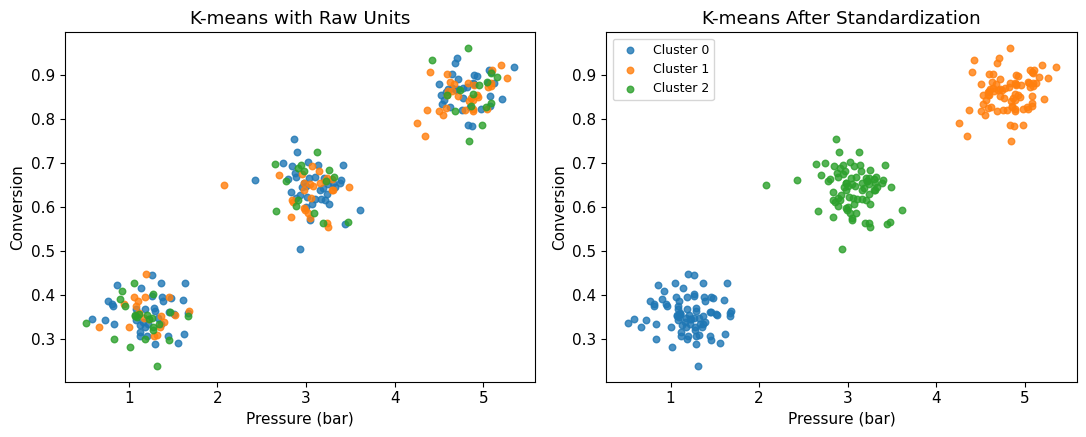

,Input representation,Agreement with known regimes (ARI)
0,Raw units,0.001
1,Standardized,1.000


In [10]:
kmeans_raw = KMeans(n_clusters=3, n_init=20, random_state=SEED)
labels_raw = kmeans_raw.fit_predict(X_reactor)

reactor_scaler = StandardScaler()
X_reactor_scaled = reactor_scaler.fit_transform(X_reactor)
kmeans_scaled = KMeans(n_clusters=3, n_init=20, random_state=SEED)
labels_scaled = kmeans_scaled.fit_predict(X_reactor_scaled)

ari_raw = adjusted_rand_score(regime_hidden, labels_raw)
ari_scaled = adjusted_rand_score(regime_hidden, labels_scaled)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
process_view = reactor_df[["pressure_bar", "conversion"]].to_numpy()
plot_clusters(axes[0], process_view, labels_raw, "K-means with Raw Units")
plot_clusters(axes[1], process_view, labels_scaled, "K-means After Standardization")
for ax in axes:
    ax.set(xlabel="Pressure (bar)", ylabel="Conversion")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Input representation": ["Raw units", "Standardized"],
    "Agreement with known regimes (ARI)": [ari_raw, ari_scaled]
}).round(3))

With raw units, temperature has too much influence on the distance. The other features have much smaller numerical values.

After standardization, the three operating regimes are much clearer.

Same data, same `k`, but different groups because we changed the feature scale.

## 5. K-medoids

K-means uses the mean as the center. That center may not be a sample we actually measured.

K-medoids uses one of the samples as the center. We call this sample the **medoid**.

For each group, choose the sample with the smallest total distance to the others:

$$\mathbf{m}_c = \underset{\mathbf{x}_j\in C_c}{\operatorname{argmin}}
\sum_{i\in C_c}d(\mathbf{x}_i,\mathbf{x}_j).$$

First, see what happens to a mean and a medoid when we add one very large value.

In [11]:
measurements = np.array([10, 11, 12, 13, 14], dtype=float)
with_outlier = np.append(measurements, 80)

representative_rows = []
for name, values in [("Original measurements", measurements),
                      ("With one extreme measurement", with_outlier)]:
    distances = np.abs(values[:, None] - values[None, :])
    medoid = values[np.argmin(distances.sum(axis=1))]
    representative_rows.append({
        "Data": name, "Mean": values.mean(), "Medoid": medoid
    })

display(pd.DataFrame(representative_rows).round(3))

,Data,Mean,Medoid
0,Original measurements,12.000,12.0
1,With one extreme measurement,23.333,12.0


The mean moved from 12 to about 23. The medoid stayed at 12.

This is one reason to use a medoid when there are outliers. There can be a tie for the best medoid too.

### Molecular Fingerprints

K-medoids can also use other distances. Let's use the Tanimoto distance from last lecture.

$$T(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad d(A,B)=1-T(A,B).$$

We make a small fingerprint with eight bits. Each bit says whether a feature is present. The last two bits describe the carbon count.

In [12]:
fingerprint_features = [
    "alcohol OH", "carbonyl", "ester", "aromatic ring",
    "nitrile", "carboxylic acid", "C1-C2", "C3+"
]

fingerprints = {
    "Methanol":       [1, 0, 0, 0, 0, 0, 1, 0],
    "Ethanol":        [1, 0, 0, 0, 0, 0, 1, 0],
    "1-Propanol":     [1, 0, 0, 0, 0, 0, 0, 1],
    "Acetone":        [0, 1, 0, 0, 0, 0, 0, 1],
    "2-Butanone":     [0, 1, 0, 0, 0, 0, 0, 1],
    "Ethyl acetate":  [0, 1, 1, 0, 0, 0, 0, 1],
    "Toluene":        [0, 0, 0, 1, 0, 0, 0, 1],
    "Ethylbenzene":   [0, 0, 0, 1, 0, 0, 0, 1],
    "Acetonitrile":   [0, 0, 0, 0, 1, 0, 1, 0],
    "Propionitrile":  [0, 0, 0, 0, 1, 0, 0, 1],
    "Acetic acid":    [0, 1, 0, 0, 0, 1, 1, 0],
    "Propionic acid": [0, 1, 0, 0, 0, 1, 0, 1]
}

names = list(fingerprints)
fingerprint_df = pd.DataFrame.from_dict(
    fingerprints, orient="index", columns=fingerprint_features
)
X_fp = fingerprint_df.to_numpy(dtype=bool)
D_fp = pairwise_distances(X_fp, metric="jaccard")

display(fingerprint_df.astype(int))
print("Methanol-Ethanol distance:", D_fp[0, 1])
print("Methanol-1-Propanol distance:", round(D_fp[0, 2], 3))

,alcohol OH,carbonyl,ester,aromatic ring,nitrile,carboxylic acid,C1-C2,C3+
Methanol,1,0,0,0,0,0,1,0
Ethanol,1,0,0,0,0,0,1,0
1-Propanol,1,0,0,0,0,0,0,1
Acetone,0,1,0,0,0,0,0,1
2-Butanone,0,1,0,0,0,0,0,1
Ethyl acetate,0,1,1,0,0,0,0,1
Toluene,0,0,0,1,0,0,0,1
Ethylbenzene,0,0,0,1,0,0,0,1
Acetonitrile,0,0,0,0,1,0,1,0
Propionitrile,0,0,0,0,1,0,0,1


Methanol-Ethanol distance: 0.0
Methanol-1-Propanol distance: 0.667


Methanol and ethanol have the same fingerprint here, so their distance is zero. These eight bits do not describe every difference between molecules.

Now choose three medoids.

We only have 12 molecules, so we can try every combination and keep the one with the smallest total distance. For a large dataset, we would use an iterative search instead.

In [13]:
def small_kmedoids(distance_matrix, k):
    best_cost = np.inf
    best_medoids = None

    for candidate in combinations(range(len(distance_matrix)), k):
        distances_to_medoids = distance_matrix[:, list(candidate)]
        total_distance = distances_to_medoids.min(axis=1).sum()
        if total_distance < best_cost:
            best_cost = total_distance
            best_medoids = list(candidate)

    labels = distance_matrix[:, best_medoids].argmin(axis=1)
    return best_medoids, labels, best_cost


medoid_ids, medoid_labels, medoid_cost = small_kmedoids(D_fp, k=3)
medoid_names = [names[i] for i in medoid_ids]

medoid_groups = pd.DataFrame({
    "Molecule": names,
    "Cluster": medoid_labels,
    "Representative": [medoid_names[c] for c in medoid_labels],
    "Distance to representative": D_fp[np.arange(len(names)),
                                        np.array(medoid_ids)[medoid_labels]]
})
print("Selected medoids:", medoid_names)
print("Total distance:", round(medoid_cost, 3))
display(medoid_groups.sort_values(["Cluster", "Molecule"]).round(3))

Selected medoids: ['Methanol', 'Acetone', 'Toluene']
Total distance: 3.417


,Molecule,Cluster,Representative,Distance to representative
2,1-Propanol,0,Methanol,0.667
10,Acetic acid,0,Methanol,0.750
8,Acetonitrile,0,Methanol,0.667
1,Ethanol,0,Methanol,0.000
0,Methanol,0,Methanol,0.000
4,2-Butanone,1,Acetone,0.000
3,Acetone,1,Acetone,0.000
5,Ethyl acetate,1,Acetone,0.333
11,Propionic acid,1,Acetone,0.333
9,Propionitrile,1,Acetone,0.667


The medoids are Methanol, Acetone, and Toluene. Each one is a molecule from our dataset.

Look at the Methanol group. It also contains acetonitrile and acetic acid. We asked for only three groups, and these molecules share some of our bits.

Try `k=4` and see which molecule becomes another medoid.

One thing to remember: `KMeans.fit(D_fp)` would treat the distance matrix as features. Use the distance matrix with a method that accepts distances, as we do here.

## 6. DBSCAN

K-means likes compact groups around a center. What if the data follow two curves?

Let's generate two curved groups and add 25 extra points. We can think of the axes as two collective variables, but the data here are generated just for this example.

DBSCAN connects points in dense regions. We choose:

- `eps`: how far to look around each point
- `min_samples`: how many points we need in that neighborhood

We do not choose the number of clusters in advance.

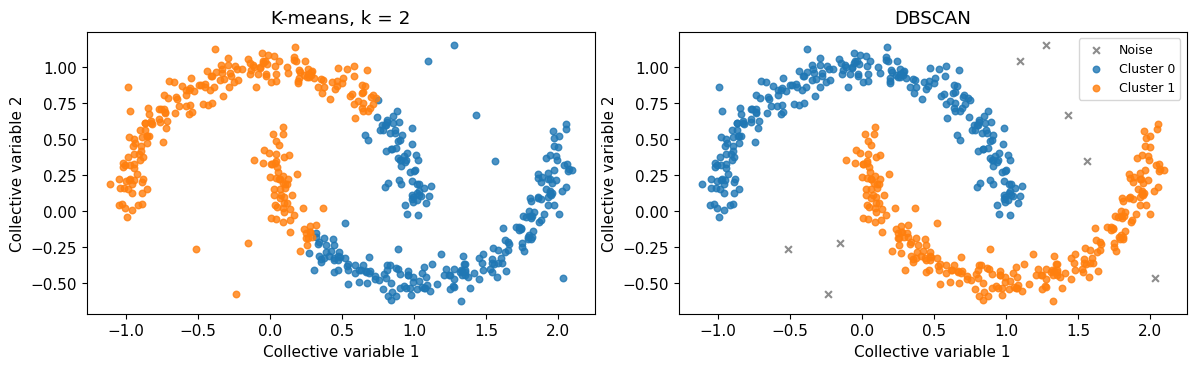

Agreement with the two generated families, using their 500 samples:
K-means ARI: 0.257
DBSCAN ARI: 1.0


In [20]:
X_curve, curve_hidden = make_moons(n_samples=500, noise=0.06, random_state=SEED)
curve_rng = np.random.default_rng(SEED)
extra_points = curve_rng.uniform([-1.2, -0.8], [2.2, 1.3], size=(25, 2))
X_curve_extra = np.vstack([X_curve, extra_points])

curve_kmeans = KMeans(n_clusters=2, n_init=20, random_state=SEED)
curve_kmeans_labels = curve_kmeans.fit_predict(X_curve_extra)

curve_dbscan = DBSCAN(eps=0.18, min_samples=8)
curve_dbscan_labels = curve_dbscan.fit_predict(X_curve_extra)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_clusters(axes[0], X_curve_extra, curve_kmeans_labels, "K-means, k = 2")
plot_clusters(axes[1], X_curve_extra, curve_dbscan_labels, "DBSCAN")
for ax in axes:
    ax.set(xlabel="Collective variable 1", ylabel="Collective variable 2")
    ax.set_aspect("equal", adjustable="box")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

print("Agreement with the two generated families, using their 500 samples:")
print("K-means ARI:", round(adjusted_rand_score(curve_hidden,
                                              curve_kmeans_labels[:500]), 3))
print("DBSCAN ARI:", round(adjusted_rand_score(curve_hidden,
                                             curve_dbscan_labels[:500]), 3))

K-means cuts across the curves. DBSCAN follows the two curves much better here.

The gray crosses are points DBSCAN calls noise. Some extra points landed near the curves, so they joined a group.

DBSCAN has three types of points:

- **Core:** enough points in its neighborhood
- **Border:** near a core point, but not enough neighbors of its own
- **Noise:** outside the connected dense groups

`min_samples` includes the point itself. Let's count the three types.

In [15]:
is_core = np.zeros(len(X_curve_extra), dtype=bool)
is_core[curve_dbscan.core_sample_indices_] = True
is_noise = curve_dbscan_labels == -1
is_border = ~is_core & ~is_noise

display(pd.DataFrame({
    "Point type": ["Core", "Border", "Noise"],
    "Count": [is_core.sum(), is_border.sum(), is_noise.sum()]
}))

print("Number of clusters:", len(set(curve_dbscan_labels) - {-1}))

,Point type,Count
0,Core,509
1,Border,8
2,Noise,8


Number of clusters: 2


### Changing the Settings

Keep the data fixed and change `eps` and `min_samples`.

The columns change `eps`. The rows change `min_samples`. Gray crosses still mean noise.

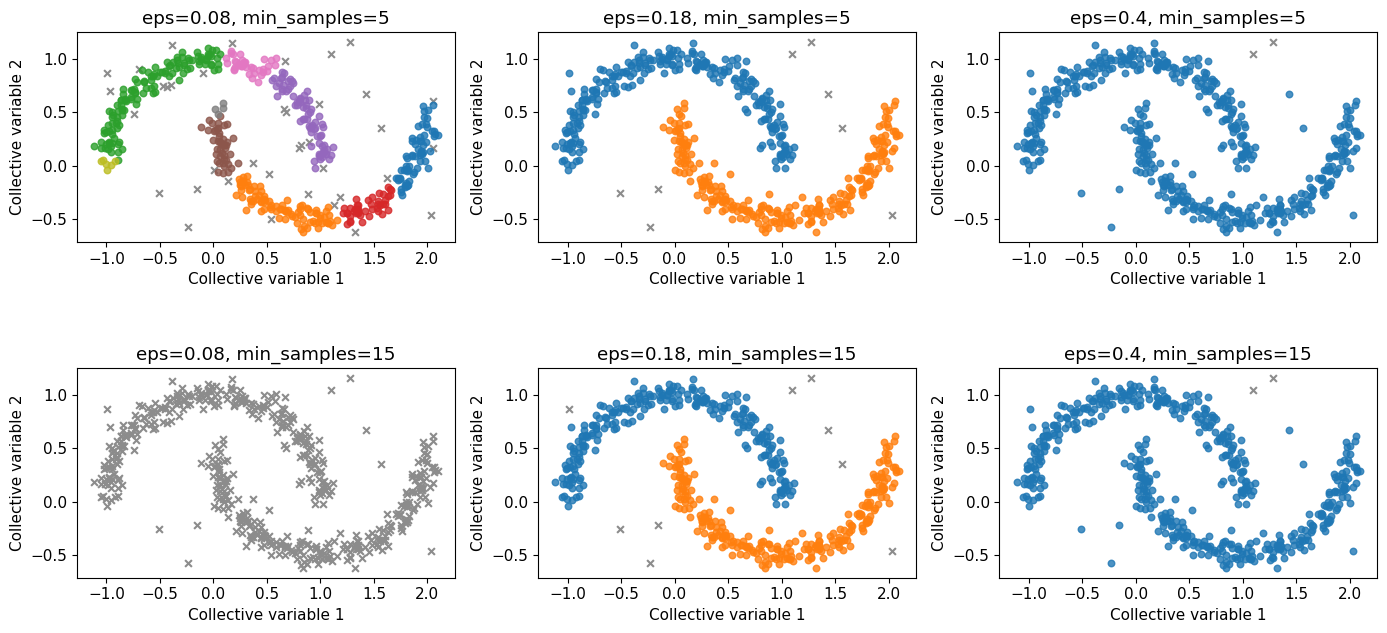

,eps,min_samples,Clusters,Noise points
0,0.08,5,9,38
1,0.18,5,2,8
2,0.40,5,1,2
3,0.08,15,0,525
4,0.18,15,2,9
5,0.40,15,1,2


In [16]:
eps_values = [0.08, 0.18, 0.40]
min_samples_values = [5, 15]
dbscan_results = []
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for row, min_samples in enumerate(min_samples_values):
    for col, eps in enumerate(eps_values):
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_curve_extra)
        n_clusters = len(set(labels) - {-1})
        dbscan_results.append({
            "eps": eps, "min_samples": min_samples,
            "Clusters": n_clusters, "Noise points": np.sum(labels == -1)
        })
        ax = axes[row, col]
        plot_clusters(ax, X_curve_extra, labels,
                      f"eps={eps:g}, min_samples={min_samples}")
        ax.set(xlabel="Collective variable 1", ylabel="Collective variable 2")
        ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
plt.show()
dbscan_results = pd.DataFrame(dbscan_results)
display(dbscan_results)

With `eps=0.08`, we get many small groups, or even all noise when `min_samples=15`.

With `eps=0.4`, the two curves connect into one group.

So DBSCAN does not need `k`, but the settings still change how many groups we get. Scaling changes the meaning of `eps` too.

A noise label does not mean the measurement is wrong. It can also be a valid state with very few nearby samples.